<a href="https://colab.research.google.com/github/jaretorx/MODELADO-Y-SOIMULACIO-NDE-SISTEMAS-MECATRONICOS-/blob/main/AF5_Sistema_a_partir_de_ecuaciones_de_Euler_Lagrane.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Figura guardada en: simulacion_pendulo_robot.png


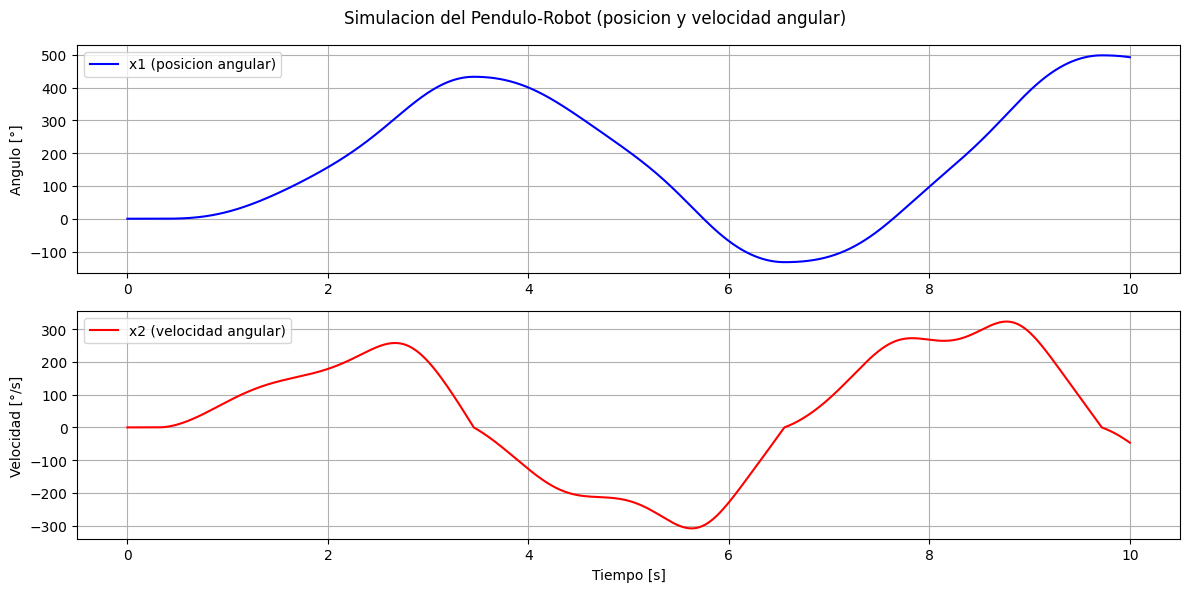

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Definimos parametros del sistema
Ir = 0.16     # Momento de inercia [kg*m^2]
m = 5.0       # Masa de todo el mecanismo [kg]
g = 9.81      # Gravedad [m/s^2]
lc = 0.01     # Distancia al centro de masa [m]
b = 0.14      # Viscosidad [N*m*s/rad]
fc = 0.45     # Friccion de Coulomb [N*m]

# Coeficientes del sistema
k1 = b / Ir
k2 = (m * g * lc) / Ir
k_fc = fc / Ir
k_tau = 1.0 / Ir

# Par aplicado por el motor
def torque_motor(t):
    return 1.5 * np.sin(t)

# Ecuaciones del sistema en Espacio de Estados
def pendulo_robot(t, x):
    x1, x2 = x  # x1: posicion angular [rad], x2: velocidad angular [rad/s]

    # Aproximacion suave de la friccion de Coulomb
    friccion_coulomb = np.tanh(100000.0 * x2)

    # Ecuaciones diferenciales de primer orden
    dx1dt = x2
    dx2dt = (
        k_tau * torque_motor(t)
        - k2 * np.sin(x1)
        - k1 * x2
        - k_fc * friccion_coulomb
    )

    return [dx1dt, dx2dt]

# Condiciones iniciales (X1 = 0, X2 = 0)
x0 = [0.0, 0.0]

# Tiempo de simulacion (10 segundos)
t_span = (0.0, 10.0)
h = 0.0025
n_puntos = int(round((t_span[1] - t_span[0]) / h)) + 1
t_eval = np.linspace(t_span[0], t_span[1], n_puntos)

# Resolver ODE
sol = solve_ivp(
    pendulo_robot,
    t_span,
    x0,
    t_eval=t_eval,
    method='RK45',
    rtol=1e-7,
    atol=1e-9
)

# Convertir resultados de radianes a grados
x1_deg = np.rad2deg(sol.y[0])
x2_deg = np.rad2deg(sol.y[1])

# Graficas
plt.figure(figsize=(12, 6))

# Posicion Angular (x1)
plt.subplot(2, 1, 1)
plt.plot(sol.t, x1_deg, label='x1 (posicion angular)', color='blue')
plt.ylabel('Angulo [°]')
plt.grid(True)
plt.legend()

# Velocidad Angular (x2)
plt.subplot(2, 1, 2)
plt.plot(sol.t, x2_deg, label='x2 (velocidad angular)', color='red')
plt.xlabel('Tiempo [s]')
plt.ylabel('Velocidad [°/s]')
plt.grid(True)
plt.legend()

plt.suptitle('Simulacion del Pendulo-Robot (posicion y velocidad angular)')
plt.tight_layout()

# Guardar la figura en un archivo
output_path = "simulacion_pendulo_robot.png"
plt.savefig(output_path)
print(f"Figura guardada en: {output_path}")
plt.show()